# 01 — Application EDA

Exploratory analysis of `application_train.csv` and `application_test.csv` — one row per current loan application (client), keyed by `SK_ID_CURR`.

## Purpose

This notebook answers application-table questions before feature engineering:

- What is the schema, missingness, and cardinality of borrower/application features?
- Is `SK_ID_CURR` unique and complete?
- How imbalanced is `TARGET`?
- Are there known anomalies?
- Which numeric features correlate most with `TARGET`?
- How redundant are building `_AVG` / `_MEDI` / `_MODE` variants?
- Which columns may act as fairness proxy candidates?

**Context:** [00_dataset_overview.ipynb](00_dataset_overview.ipynb) · [docs/glossary.md](../../docs/glossary.md) · `data/HomeCredit_columns_description.csv`

## Out of scope

- Credit scoring model training
- Null-importance feature selection
- Fairness metrics / mitigation → later pipeline


## 0. Schema

Load the application train and test tables and record how many rows and columns each split has.

In [1]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_rows", 50)
pd.set_option("display.max_colwidth", 80)

HIGH_MISSINGNESS_THRESHOLD = 0.50
PRIMARY_KEY = "SK_ID_CURR"

_cwd = Path.cwd()
if not (_cwd / "data" / "application_train.csv").exists():
    repo_root = (_cwd / "../..").resolve()
    if (repo_root / "data" / "application_train.csv").exists():
        os.chdir(repo_root)
    else:
        raise FileNotFoundError(
            "Place Home Credit CSVs in data/ and run with repo root or analysis/notebooks/ as cwd."
        )

DATA_DIR = Path("data")

def load_application_tables(data_dir: Path) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    paths = {
        "train": data_dir / "application_train.csv",
        "test": data_dir / "application_test.csv",
    }
    missing = [name for name, p in paths.items() if not p.exists()]
    if missing:
        raise FileNotFoundError(f"Missing files in {data_dir}: {missing}")

    train = pd.read_csv(paths["train"])
    test = pd.read_csv(paths["test"])
    return train, test


train, test = load_application_tables(DATA_DIR)

for name, df in [("train", train), ("test", test)]:
    print(f"{name}: {df.shape[0]:,} rows x {df.shape[1]} cols")



train: 307,511 rows x 122 cols
test: 48,744 rows x 121 cols


## 1. Missingness

Find columns with very high missing rates (>50%) in test and compare which high-missing columns appear in train only, test only, or both. Also prints all columns with >50% missing in train data.

In [2]:
def schema_summary(df: pd.DataFrame, table_name: str) -> pd.DataFrame:
    rows = []
    n = len(df)
    for col in df.columns:
        missing = int(df[col].isna().sum())
        n_unique = int(df[col].nunique(dropna=True))
        rows.append(
            {
                "table": table_name,
                "column": col,
                "dtype": str(df[col].dtype),
                "%missing": round(100 * missing / n, 2) if n else 0.0,
                "%unique": round(100 * n_unique / n, 2) if n else 0.0,
            }
        )
    return pd.DataFrame(rows)


schema = pd.concat(
    [schema_summary(train, "train"), schema_summary(test, "test")],
    ignore_index=True,
)

MISSING_TABLE_COLS = ["table", "column", "dtype", "%missing", "%unique"]
missing_threshold_pct = HIGH_MISSINGNESS_THRESHOLD * 100


def display_missing_table(df: pd.DataFrame) -> None:
    display(
        df[MISSING_TABLE_COLS]
        .style.hide(axis="index")
        .format({"%missing": "{:.2f}", "%unique": "{:.2f}"})
    )


train_high = set(
    schema.loc[
        (schema["table"] == "train") & (schema["%missing"] > missing_threshold_pct),
        "column",
    ]
)
test_high = set(
    schema.loc[
        (schema["table"] == "test") & (schema["%missing"] > missing_threshold_pct),
        "column",
    ]
)
both_high = train_high & test_high
train_only_high = train_high - test_high
test_only_high = test_high - train_high

print(f"Columns with >{missing_threshold_pct:.0f}% missing:")
print(f"  Both train and test: {len(both_high)}")
print(f"  Train only: {len(train_only_high)}")
print(f"  Test only: {len(test_only_high)}")

print(
    f"\nTrain columns with >{missing_threshold_pct:.0f}% missing "
    f"({len(train_high)} columns):"
)
high_missing_test = schema[
    (schema["table"] == "train") & (schema["%missing"] > missing_threshold_pct)
].sort_values("%missing", ascending=False)
display_missing_table(high_missing_test)

Columns with >50% missing:
  Both train and test: 29
  Train only: 12
  Test only: 0

Train columns with >50% missing (41 columns):


table,column,dtype,%missing,%unique
train,COMMONAREA_AVG,float64,69.87,1.03
train,COMMONAREA_MEDI,float64,69.87,1.04
train,COMMONAREA_MODE,float64,69.87,1.02
train,NONLIVINGAPARTMENTS_AVG,float64,69.43,0.13
train,NONLIVINGAPARTMENTS_MODE,float64,69.43,0.05
train,NONLIVINGAPARTMENTS_MEDI,float64,69.43,0.07
train,FONDKAPREMONT_MODE,str,68.39,0.00
train,LIVINGAPARTMENTS_AVG,float64,68.35,0.61
train,LIVINGAPARTMENTS_MODE,float64,68.35,0.24
train,LIVINGAPARTMENTS_MEDI,float64,68.35,0.36


## 2. Key and target integrity

Check that `SK_ID_CURR` is complete and unique in each split, and that `TARGET` in train contains only 0 and 1.

In [3]:
def key_integrity(df: pd.DataFrame, key: str, label: str) -> pd.DataFrame:
    return pd.DataFrame(
        [
            {
                "split": label,
                "null_keys": int(df[key].isna().sum()),
                "duplicate_keys": int(df[key].duplicated().sum()),
            }
        ]
    )


integrity = pd.concat([key_integrity(train, PRIMARY_KEY, "train"), key_integrity(test, PRIMARY_KEY, "test")])
integrity

if "TARGET" in train.columns:
    target_values = sorted(train["TARGET"].dropna().unique())
    print(f"TARGET unique values: {target_values}")
    assert set(target_values).issubset({0, 1}), "Unexpected TARGET values"


TARGET unique values: [np.int64(0), np.int64(1)]


## 3. Cardinality and numeric summaries

See how many distinct values each categorical column takes and skim basic distribution stats for numeric columns.

In [4]:
cat_cols = train.select_dtypes(include=["object", "string"]).columns.tolist()
cardinality = (
    train[cat_cols]
    .nunique(dropna=True)
    .sort_values(ascending=False)
    .rename("n_unique")
    .reset_index()
    .rename(columns={"index": "column"})
)
cardinality.head(15)


,column,n_unique
0,ORGANIZATION_TYPE,58
1,OCCUPATION_TYPE,18
2,NAME_INCOME_TYPE,8
3,NAME_TYPE_SUITE,7
4,WALLSMATERIAL_MODE,7
5,WEEKDAY_APPR_PROCESS_START,7
6,NAME_FAMILY_STATUS,6
7,NAME_HOUSING_TYPE,6
8,NAME_EDUCATION_TYPE,5
9,FONDKAPREMONT_MODE,4


Summarize count, mean, and spread for every numeric column in train. A low `count` flags columns with missing values; min and max help spot scale and extreme values.

In [5]:
numeric_cols = train.select_dtypes(include=[np.number]).columns.tolist()
train[numeric_cols].describe().T.sort_values("count")


,count,mean,std,min,25%,50%,75%,max
COMMONAREA_MODE,92646.0,0.042553,0.074445,0.0,0.0072,0.0190,0.0490,1.0
COMMONAREA_AVG,92646.0,0.044621,0.076036,0.0,0.0078,0.0211,0.0515,1.0
COMMONAREA_MEDI,92646.0,0.044595,0.076144,0.0,0.0079,0.0208,0.0513,1.0
NONLIVINGAPARTMENTS_AVG,93997.0,0.008809,0.047732,0.0,0.0000,0.0000,0.0039,1.0
NONLIVINGAPARTMENTS_MEDI,93997.0,0.008651,0.047415,0.0,0.0000,0.0000,0.0039,1.0
...,...,...,...,...,...,...,...,...
FLAG_DOCUMENT_12,307511.0,0.000007,0.002550,0.0,0.0000,0.0000,0.0000,1.0
FLAG_DOCUMENT_21,307511.0,0.000335,0.018299,0.0,0.0000,0.0000,0.0000,1.0
FLAG_DOCUMENT_20,307511.0,0.000507,0.022518,0.0,0.0000,0.0000,0.0000,1.0
FLAG_DOCUMENT_18,307511.0,0.008130,0.089798,0.0,0.0000,0.0000,0.0000,1.0


## 4. TARGET class distribution

Measure how often loans default in the training set and visualize the split between `TARGET=0` and `TARGET=1`.

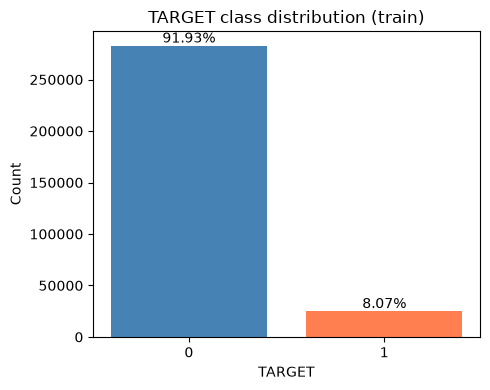

In [6]:
target_counts = train["TARGET"].value_counts().sort_index()
target_pct = (100 * train["TARGET"].value_counts(normalize=True)).round(2)
target_summary = pd.DataFrame({"count": target_counts, "pct": target_pct})
target_summary

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(target_summary.index.astype(str), target_summary["count"], color=["steelblue", "coral"])
ax.set_xlabel("TARGET")
ax.set_ylabel("Count")
ax.set_title("TARGET class distribution (train)")
for i, (idx, row) in enumerate(target_summary.iterrows()):
    ax.text(i, row["count"], f"{row['pct']}%", ha="center", va="bottom")
plt.tight_layout()
plt.show()


Minority of the clients have dificulties to repay the loan.

## 5. Anomalies: DAYS_EMPLOYED sentinel

Look for implausible employment lengths in `DAYS_EMPLOYED` that likely encode “unknown” rather than a real duration.

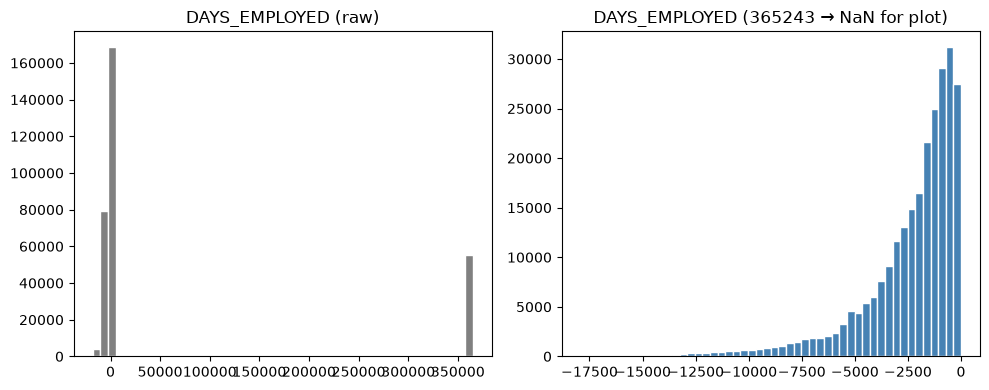

In [7]:
train["DAYS_EMPLOYED"].describe()

IMPLAUSIBLE_DAYS_THRESHOLD = 50 * 365
implausible = train.loc[train["DAYS_EMPLOYED"] > IMPLAUSIBLE_DAYS_THRESHOLD, "DAYS_EMPLOYED"]
implausible_counts = implausible.value_counts()

if implausible_counts.empty:
    raise ValueError("No implausible DAYS_EMPLOYED values found above threshold.")

DAYS_EMPLOYED_ANOMALY = implausible_counts.index[0]


def days_employed_anomaly_report(train_df: pd.DataFrame, test_df: pd.DataFrame, sentinel) -> pd.DataFrame:
    rows = []
    for label, df in [("train", train_df), ("test", test_df)]:
        n = len(df)
        n_anom = int((df["DAYS_EMPLOYED"] == sentinel).sum())
        rows.append(
            {
                "split": label,
                "sentinel": sentinel,
                "anomaly_count": n_anom,
                "anomaly_pct": round(100 * n_anom / n, 2),
            }
        )
    return pd.DataFrame(rows)


anomaly_report = days_employed_anomaly_report(train, test, DAYS_EMPLOYED_ANOMALY)
anomaly_report

anom = train[train["DAYS_EMPLOYED"] == DAYS_EMPLOYED_ANOMALY]
non_anom = train[train["DAYS_EMPLOYED"] != DAYS_EMPLOYED_ANOMALY]
default_rate_by_group = pd.DataFrame(
    {
        "group": ["non_anomaly", "anomaly"],
        "n_rows": [len(non_anom), len(anom)],
        "default_rate_pct": [
            round(100 * non_anom["TARGET"].mean(), 2),
            round(100 * anom["TARGET"].mean(), 2),
        ],
    }
)
default_rate_by_group

days_for_plot = train["DAYS_EMPLOYED"].replace(DAYS_EMPLOYED_ANOMALY, np.nan)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(train["DAYS_EMPLOYED"], bins=50, color="gray", edgecolor="white")
axes[0].set_title("DAYS_EMPLOYED (raw)")
axes[1].hist(days_for_plot.dropna(), bins=50, color="steelblue", edgecolor="white")
axes[1].set_title(f"DAYS_EMPLOYED ({DAYS_EMPLOYED_ANOMALY} → NaN for plot)")
plt.tight_layout()
plt.show()


All values above ~50 years of employment share a single sentinel (`365243` in the output above). It appears in both train and test at similar rates and is visible as a spike in the raw histogram. Default rate is lower in the anomaly group than elsewhere, so the value likely encodes unknown or non-standard employment rather than true tenure.


## 6. Correlations with TARGET

Rank numeric features by linear correlation with default risk to spot the strongest positive and negative relationships.

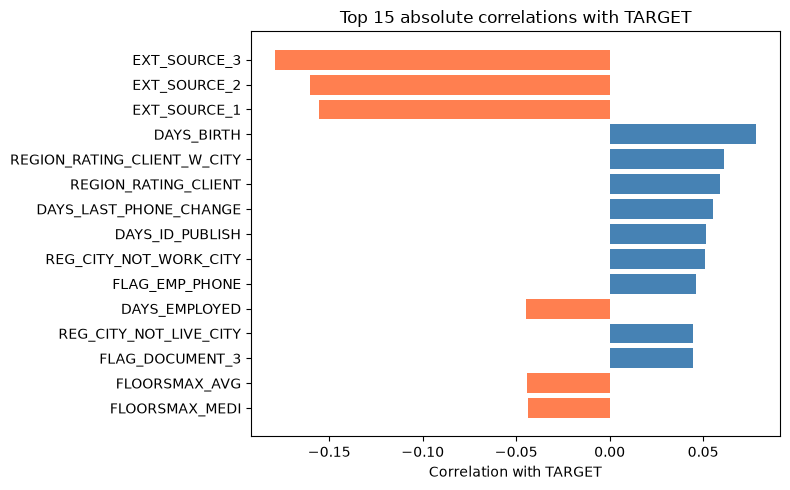

In [8]:
numeric_train = train.select_dtypes(include=[np.number])
target_corr = numeric_train.corr(numeric_only=True)["TARGET"].drop("TARGET", errors="ignore").sort_values()

top_neg = target_corr.head(10)
top_pos = target_corr.tail(10)
pd.DataFrame({"most_negative": top_neg, "most_positive": top_pos})

plot_corr = target_corr.abs().sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(8, 5))
colors = ["coral" if target_corr[c] < 0 else "steelblue" for c in plot_corr.index]
ax.barh(plot_corr.index[::-1], [target_corr[c] for c in plot_corr.index[::-1]], color=colors[::-1])
ax.set_xlabel("Correlation with TARGET")
ax.set_title("Top 15 absolute correlations with TARGET")
plt.tight_layout()
plt.show()


Exploratory only — not feature selection. Strong correlations (e.g. `EXT_SOURCE_*`) should be checked against column descriptions for leakage risk before modeling.


## 7. Building _AVG / _MEDI / _MODE redundancy

Group building columns that share a base name across `_AVG`, `_MEDI`, and `_MODE` suffixes and measure how correlated those variants are.

In [9]:
def building_suffix_groups(columns: list[str]) -> dict[str, list[str]]:
    suffixes = ("_AVG", "_MEDI", "_MODE")
    groups: dict[str, list[str]] = {}
    for col in columns:
        for suf in suffixes:
            if col.endswith(suf):
                base = col[: -len(suf)]
                groups.setdefault(base, []).append(col)
    return {k: sorted(v) for k, v in groups.items() if len(v) > 1}


building_groups = building_suffix_groups(train.columns.tolist())
print(f"Building attribute groups with multiple suffix variants: {len(building_groups)}")

redundancy_rows = []
for base, cols in building_groups.items():
    sub = train[cols].select_dtypes(include=[np.number])
    if sub.shape[1] < 2:
        continue
    corr = sub.corr()
    pairs = []
    for i, c1 in enumerate(cols):
        for c2 in cols[i + 1 :]:
            if c1 in corr.columns and c2 in corr.columns:
                pairs.append(abs(corr.loc[c1, c2]))
    if pairs:
        redundancy_rows.append(
            {
                "base": base,
                "variants": ", ".join(cols),
                "n_variants": len(cols),
                "min_abs_corr": round(min(pairs), 3),
                "mean_abs_corr": round(float(np.mean(pairs)), 3),
                "max_abs_corr": round(max(pairs), 3),
            }
        )

redundancy_df = pd.DataFrame(redundancy_rows).sort_values("mean_abs_corr", ascending=False)
redundancy_df.head(15).style.hide(axis="index")


Building attribute groups with multiple suffix variants: 14


base,variants,n_variants,min_abs_corr,mean_abs_corr,max_abs_corr
YEARS_BUILD,"YEARS_BUILD_AVG, YEARS_BUILD_MEDI, YEARS_BUILD_MODE",3,0.989000,0.992000,0.998000
FLOORSMIN,"FLOORSMIN_AVG, FLOORSMIN_MEDI, FLOORSMIN_MODE",3,0.986000,0.991000,0.997000
FLOORSMAX,"FLOORSMAX_AVG, FLOORSMAX_MEDI, FLOORSMAX_MODE",3,0.986000,0.990000,0.997000
ELEVATORS,"ELEVATORS_AVG, ELEVATORS_MEDI, ELEVATORS_MODE",3,0.979000,0.986000,0.996000
ENTRANCES,"ENTRANCES_AVG, ENTRANCES_MEDI, ENTRANCES_MODE",3,0.978000,0.985000,0.997000
COMMONAREA,"COMMONAREA_AVG, COMMONAREA_MEDI, COMMONAREA_MODE",3,0.977000,0.984000,0.996000
APARTMENTS,"APARTMENTS_AVG, APARTMENTS_MEDI, APARTMENTS_MODE",3,0.973000,0.982000,0.995000
BASEMENTAREA,"BASEMENTAREA_AVG, BASEMENTAREA_MEDI, BASEMENTAREA_MODE",3,0.973000,0.982000,0.994000
LANDAREA,"LANDAREA_AVG, LANDAREA_MEDI, LANDAREA_MODE",3,0.974000,0.982000,0.992000
LIVINGAREA,"LIVINGAREA_AVG, LIVINGAREA_MEDI, LIVINGAREA_MODE",3,0.972000,0.981000,0.996000


Per [docs/glossary.md](../../docs/glossary.md): `_AVG` (normal-like), `_MEDI` (skewed), `_MODE` (discrete). Variants within a group are typically highly correlated; FE may keep one representative later.


## 8. Protected attributes and fairness proxy candidates

Profile the protected attributes (gender, age) and likely proxies (occupation, income, region). The protected attributes are model features and are also kept raw for fairness grouping; the detailed audit is in `07_protected_attributes.ipynb`.

CODE_GENDER counts:
CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64


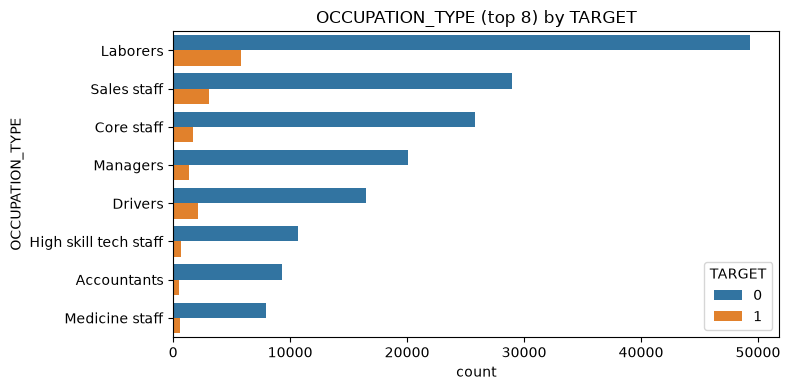

In [10]:
PROTECTED = ["CODE_GENDER", "DAYS_BIRTH"]
PROXY_CANDIDATES = [
    "NAME_EDUCATION_TYPE",
    "OCCUPATION_TYPE",
    "ORGANIZATION_TYPE",
    "NAME_INCOME_TYPE",
    "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE",
    "AMT_INCOME_TOTAL",
] + [c for c in train.columns if c.startswith("REGION_")]

audit_cols = [c for c in PROTECTED + PROXY_CANDIDATES if c in train.columns]
proxy_profile = schema[schema["column"].isin(audit_cols) & (schema["table"] == "train")][
    ["column", "dtype", "%missing", "%unique"]
].sort_values("column")
proxy_profile

if "CODE_GENDER" in train.columns:
    print("CODE_GENDER counts:")
    print(train["CODE_GENDER"].value_counts(dropna=False))

fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=train, y="OCCUPATION_TYPE", hue="TARGET", order=train["OCCUPATION_TYPE"].value_counts().head(8).index)
ax.set_title("OCCUPATION_TYPE (top 8) by TARGET")
plt.tight_layout()
plt.show()


`CODE_GENDER` and age (`DAYS_BIRTH`) are protected attributes. Per project decisions they are **included** in the model features and kept raw for fairness grouping (gender × 10-year age bands). Proxy candidates are profiled in `07_protected_attributes.ipynb` — not removed or mitigated here.

## Summary of findings

_Executed successfully on 2026-10-18._

- **Train / test:** 307,511 × 122 and 48,744 × 121; 121 shared columns; only `TARGET` is train-only. `SK_ID_CURR` has no nulls or duplicates in either split.
- **TARGET imbalance:** ~8.1% defaults (`TARGET=1`) vs ~91.9% non-defaults — minority positive class.
- **Missingness:** 41 train columns (mostly building `_AVG`/`_MEDI`/`_MODE` and `OWN_CAR_AGE`) have ≥50% missing; imputation or exclusion decisions belong in the feature pipeline (`src/features/`).
- **DAYS_EMPLOYED anomaly:** Discovered sentinel `365243` (values >50 years employment); 55,374 train rows (18.0%) and 9,274 test rows (19.0%); anomaly default rate 5.4% vs 8.7% for non-anomaly rows. FE should add indicator + replace sentinel.
- **Correlations with TARGET:** Strongest negative: `EXT_SOURCE_3` (−0.18), `EXT_SOURCE_2` (−0.16), `EXT_SOURCE_1` (−0.16). Strongest positive among top features: `DAYS_BIRTH` (+0.08). Exploratory only — verify meanings before modeling.
- **Building redundancy:** 14 attribute groups have all three `_AVG`/`_MEDI`/`_MODE` variants; mean pairwise |r| often >0.98 — keep one variant per group in FE.
- **Fairness audit inputs:** `CODE_GENDER` (4 `XNA` rows, excluded before training and evaluation) and age from `DAYS_BIRTH`, plus proxy candidates (`NAME_EDUCATION_TYPE`, `OCCUPATION_TYPE`, `ORGANIZATION_TYPE`, `NAME_INCOME_TYPE`, `REGION_*`, income/housing) profiled in `07_protected_attributes.ipynb`.
